In [8]:
# Cell 1: load all CSVs
import pandas as pd, numpy as np, glob
import matplotlib.pyplot as plt, seaborn as sns

files = glob.glob("../data/*.csv")
print(len(files), "files found")

df = pd.concat((pd.read_csv(f, low_memory=False) for f in files), ignore_index=True)
df.columns = df.columns.str.strip()   # column names have leading spaces
print(df.shape)

8 files found
(2830743, 79)


In [9]:
# Cell 2: clean
df = df.replace([np.inf, -np.inf], np.nan)
print("NaN rows:", df.isna().any(axis=1).sum())
print("Duplicates:", df.duplicated().sum())
df = df.dropna().drop_duplicates().reset_index(drop=True)
print(df.shape)

NaN rows: 2867
Duplicates: 308381
(2520798, 79)


Label
BENIGN                        2095057
DoS Hulk                       172846
DDoS                           128014
PortScan                        90694
DoS GoldenEye                   10286
FTP-Patator                      5931
DoS slowloris                    5385
DoS Slowhttptest                 5228
SSH-Patator                      3219
Bot                              1948
Web Attack � Brute Force         1470
Web Attack � XSS                  652
Infiltration                       36
Web Attack � Sql Injection         21
Heartbleed                         11
Name: count, dtype: int64


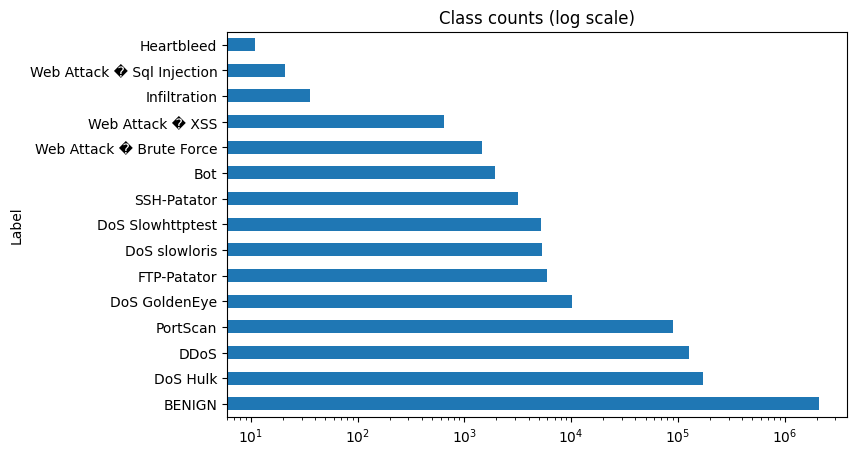

In [10]:
# Cell 3: class balance
counts = df["Label"].value_counts()
print(counts)
counts.plot(kind="barh", logx=True, figsize=(8,5), title="Class counts (log scale)")
plt.show()

In [11]:
# Cell 4: binary view + save a sample for fast experiments
df["is_attack"] = (df["Label"] != "BENIGN").astype(int)
print(df["is_attack"].value_counts(normalize=True))

# keep all rows of rare attacks, sample the big classes
sample = (df.groupby("Label", group_keys=False)
            .apply(lambda g: g.sample(min(len(g), 50000), random_state=42)))
print(sample.shape)
sample.to_parquet("../data/sample.parquet")   # needs: pip install pyarrow

is_attack
0    0.831109
1    0.168891
Name: proportion, dtype: float64


C:\Users\Robin Yadav\AppData\Local\Temp\ipykernel_28312\4107997699.py:7: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(min(len(g), 50000), random_state=42)))


(234187, 80)


In [12]:
# Cell 5: quick feature look
print(df.dtypes.value_counts())
corr = df.drop(columns=["Label"]).corr(numeric_only=True)["is_attack"].abs().sort_values(ascending=False)
print(corr.head(15))


int64      55
float64    24
object      1
Name: count, dtype: int64
is_attack                 1.000000
Bwd Packet Length Std     0.611719
Bwd Packet Length Max     0.596472
Bwd Packet Length Mean    0.594413
Avg Bwd Segment Size      0.594413
Packet Length Std         0.573487
Max Packet Length         0.555474
Packet Length Variance    0.536776
Average Packet Size       0.521616
Packet Length Mean        0.520950
Fwd IAT Std               0.506110
Idle Max                  0.475610
Flow IAT Max              0.471520
Idle Mean                 0.470861
Fwd IAT Max               0.470800
Name: is_attack, dtype: float64
